# EDA — Law database cho Subtask 1

Khảo sát `data/law_db/vlsp2025_law.json` trước khi xây corpus retrieval.

**Mục tiêu:** hiểu cấu trúc, kiểm tra định danh, khảo sát văn bản/bảng/ảnh và xác định các quyết định tiền xử lý. Notebook chỉ đọc dữ liệu, không sửa nhãn, không gộp hay ghi đè bản ghi.

Chạy các cell theo thứ tự. Notebook dùng `pandas`, `matplotlib` và `IPython`; nếu thiếu thư viện, bỏ dấu `#` trong cell cài đặt bên dưới rồi chạy. Các thống kê độ dài/tokens chỉ là thống kê mô tả, chưa phải tokenizer của mô hình.


In [1]:
import json
import re
import unicodedata
from collections import Counter
from html.parser import HTMLParser
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option('display.max_colwidth', 110)

# Hỗ trợ kernel khởi chạy tại project root hoặc notebooks/.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data/law_db/vlsp2025_law.json').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Không tìm thấy data/law_db/vlsp2025_law.json từ thư mục hiện tại.')
LAW_DIR = ROOT / 'data' / 'law_db'
LAW_PATH = LAW_DIR / 'vlsp2025_law.json'
print('Project root:', ROOT)
print('Law JSON:', LAW_PATH)


Project root: c:\Users\long3\Documents\Multimodal QA
Law JSON: c:\Users\long3\Documents\Multimodal QA\data\law_db\vlsp2025_law.json


## 1. Cấu trúc dữ liệu gốc

JSON là danh sách văn bản luật. Mỗi văn bản có `id`, `title`, `articles`; mỗi điều/mục có `id`, `title`, `text`. Không in toàn bộ JSON vì có các trường văn bản rất dài.


In [2]:
with LAW_PATH.open(encoding='utf-8-sig') as f:
    laws = json.load(f)

assert isinstance(laws, list) and laws, 'Dữ liệu phải là danh sách không rỗng.'
structure = []
for law_idx, law in enumerate(laws):
    assert isinstance(law, dict), f'Văn bản {law_idx} không phải object.'
    assert {'id', 'title', 'articles'} <= law.keys(), f'Văn bản {law_idx} thiếu trường.'
    assert isinstance(law['articles'], list), f'articles của văn bản {law_idx} không phải list.'
    structure.append({
        'law_idx': law_idx,
        'law_id': law['id'],
        'law_title': law['title'],
        'article_records': len(law['articles']),
    })
laws_df = pd.DataFrame(structure)
display(laws_df)
print('Trường cấp văn bản:', [list(law) for law in laws])


,law_idx,law_id,law_title,article_records
0,0,QCVN 41:2024/BGTVT,QUY CHUẨN KỸ THUẬT QUỐC GIA VỀ BÁO HIỆU ĐƯỜNG BỘ,313
1,1,36/2024/QH15,"LUẬT TRẬT TỰ, AN TOÀN GIAO THÔNG ĐƯỜNG BỘ",89


Trường cấp văn bản: [['id', 'title', 'articles'], ['id', 'title', 'articles']]


## 2. Tạo bảng phẳng và kiểm tra schema

Mỗi dòng vẫn tương ứng với một bản ghi gốc. Giữ `law_idx`, `article_idx`, `json_path` để truy ngược vị trí; không dùng dictionary theo ID ở bước này vì có thể làm mất các bản ghi trùng khóa.


In [3]:
rows = []
for law_idx, law in enumerate(laws):
    for article_idx, article in enumerate(law['articles']):
        if not isinstance(article, dict):
            raise TypeError(f'$[{law_idx}].articles[{article_idx}] không phải object.')
        rows.append({
            'law_idx': law_idx,
            'article_idx': article_idx,
            'json_path': f'$[{law_idx}].articles[{article_idx}]',
            'law_id': law['id'],
            'law_title': law['title'],
            'article_id': article.get('id'),
            'title': article.get('title'),
            'text': article.get('text'),
            'missing_fields': sorted({'id', 'title', 'text'} - article.keys()),
        })
articles = pd.DataFrame(rows)
assert not articles.empty, 'Corpus không có bản ghi điều luật.'

schema_issues = articles[
    articles['missing_fields'].map(bool)
    | ~articles['law_id'].map(lambda v: isinstance(v, str) and bool(v.strip()))
    | ~articles['article_id'].map(lambda v: isinstance(v, str) and bool(v.strip()))
    | ~articles['title'].map(lambda v: isinstance(v, str))
    | ~articles['text'].map(lambda v: isinstance(v, str))
]
display(schema_issues[['json_path', 'law_id', 'article_id', 'missing_fields']])
assert schema_issues.empty, 'Có vấn đề schema; kiểm tra các dòng ở trên trước khi tiếp tục.'

display(articles[['json_path', 'law_id', 'article_id', 'title']].head(10))
print('Tổng bản ghi:', len(articles))
print('Cặp ID duy nhất:', len(articles[['law_id', 'article_id']].drop_duplicates()))
print('ID văn bản luật có trùng:', laws_df['law_id'].duplicated().any())


,json_path,law_id,article_id,missing_fields


,json_path,law_id,article_id,title
0,$[0].articles[0],QCVN 41:2024/BGTVT,1,Phạm vi điều chỉnh
1,$[0].articles[1],QCVN 41:2024/BGTVT,2,Đối tượng áp dụng
2,$[0].articles[2],QCVN 41:2024/BGTVT,3,Giải thích từ ngữ
3,$[0].articles[3],QCVN 41:2024/BGTVT,4,Thứ tự hiệu lực của hệ thống báo hiệu
4,$[0].articles[4],QCVN 41:2024/BGTVT,5,Thứ tự đường ưu tiên
5,$[0].articles[5],QCVN 41:2024/BGTVT,6,Điều khiển giao thông bằng tín hiệu đèn
6,$[0].articles[6],QCVN 41:2024/BGTVT,7,Xe ưu tiên và tín hiệu của xe ưu tiên
7,$[0].articles[7],QCVN 41:2024/BGTVT,8,Hiệu lực của đèn tín hiệu
8,$[0].articles[8],QCVN 41:2024/BGTVT,9,Vị trí và độ cao đặt đèn tín hiệu
9,$[0].articles[9],QCVN 41:2024/BGTVT,10,"Kích thước, hình dạng và các quy định khác của đèn tín hiệu"


Tổng bản ghi: 402
Cặp ID duy nhất: 398
ID văn bản luật có trùng: False


## 3. ID trùng, trường rỗng và nội dung trùng

Khóa retrieval là `(law_id, article_id)`. Kiểm tra trực tiếp file hiện tại: nhóm `K.1` và `K.2` có nhiều bản ghi; đây là vấn đề định danh cần xem xét, không có nghĩa nội dung các bản ghi giống nhau. Chỉ số trong JSON path bắt đầu từ 0.


In [4]:
key = ['law_id', 'article_id']
duplicate_ids = articles[articles.duplicated(key, keep=False)].copy()
display(duplicate_ids[['json_path', 'law_id', 'article_id', 'title']])

for column in ['title', 'text']:
    empty = articles[articles[column].str.strip().eq('')]
    print(f'{column}: {len(empty)} bản ghi rỗng')
    display(empty[['json_path', 'law_id', 'article_id']].head(20))

# So sánh nội dung sau chuẩn hóa Unicode và khoảng trắng; không thay đổi dữ liệu gốc.
normalized_text = articles['text'].map(
    lambda text: re.sub(r'\s+', ' ', unicodedata.normalize('NFC', text)).strip()
)
nonempty = normalized_text.ne('')
text_duplicates = articles[nonempty & normalized_text.duplicated(keep=False)]
print('Số bản ghi có nội dung không rỗng trùng nhau:', len(text_duplicates))
display(text_duplicates[['json_path', 'law_id', 'article_id', 'title']].head(30))


,json_path,law_id,article_id,title
275,$[0].articles[275],QCVN 41:2024/BGTVT,K.1,K.1 Kiểu chữ thường (gt2)
276,$[0].articles[276],QCVN 41:2024/BGTVT,K.1,"K.1.1 Chữ in hoa, kiểu chữ thường (gt2)"
277,$[0].articles[277],QCVN 41:2024/BGTVT,K.1,"K.1.2 Chữ thường, kiểu chữ thường (gt2)"
278,$[0].articles[278],QCVN 41:2024/BGTVT,K.2,K.2 Kiểu chữ nén (gt1)
279,$[0].articles[279],QCVN 41:2024/BGTVT,K.2,"K.2.1 Chữ in hoa, kiểu chữ nén (gt1)"
280,$[0].articles[280],QCVN 41:2024/BGTVT,K.2,"K.2.2 Chữ thường, kiểu chữ nén (gt1)"


title: 0 bản ghi rỗng


,json_path,law_id,article_id


text: 0 bản ghi rỗng


,json_path,law_id,article_id


Số bản ghi có nội dung không rỗng trùng nhau: 0


,json_path,law_id,article_id,title


## 4. Marker ảnh và bảng HTML

Văn bản corpus chứa các marker `<<IMAGE: ... /IMAGE>>`, `<<TABLE: ... /TABLE>>` và HTML. Đếm marker riêng với số thẻ `<table>` vì hai đại lượng có thể khác nhau.


In [5]:
IMAGE_PATTERN = re.compile(r'<<IMAGE:\s*(.*?)\s*/IMAGE>>', re.DOTALL)
articles['n_image_refs'] = articles['text'].map(lambda text: len(IMAGE_PATTERN.findall(text)))
articles['n_table_markers'] = articles['text'].str.count(r'<<TABLE:')
articles['n_html_tables'] = articles['text'].str.count(r'(?i)<table\b')
articles['has_html'] = articles['text'].str.contains(r'<[A-Za-z][^>]*>', regex=True)
articles['raw_chars'] = articles['text'].str.len()

summary = articles.groupby('law_id').agg(
    records=('article_id', 'size'),
    raw_chars=('raw_chars', 'sum'),
    records_with_images=('n_image_refs', lambda s: int((s > 0).sum())),
    image_references=('n_image_refs', 'sum'),
    records_with_tables=('n_html_tables', lambda s: int((s > 0).sum())),
    html_tables=('n_html_tables', 'sum'),
)
display(summary)
display(articles.loc[articles['n_html_tables'] > 0,
    ['law_id', 'article_id', 'title', 'raw_chars', 'n_html_tables']].head(10))


,records,raw_chars,records_with_images,image_references,records_with_tables,html_tables
law_id,,,,,,
36/2024/QH15,89,155720,0,0,0,0
QCVN 41:2024/BGTVT,313,2630127,230,761,42,424


,law_id,article_id,title,raw_chars,n_html_tables
11,QCVN 41:2024/BGTVT,12,Kích thước của biển báo,43865,4
45,QCVN 41:2024/BGTVT,46,Nội dung biển chỉ dẫn trên đường cao tốc,199497,10
46,QCVN 41:2024/BGTVT,47,Các loại biển chỉ dẫn trên đường cao tốc,32929,4
55,QCVN 41:2024/BGTVT,56,Tiêu phản quang,22978,2
85,QCVN 41:2024/BGTVT,A.2,A.2 Một số quy định khi sử dụng hệ thống đèn tín hiệu,11889,2
98,QCVN 41:2024/BGTVT,B.10,"B.10 Biển số P.110a ""Cấm xe đạp"" và Biển số P.110b""Cấm xe đạp thồ""",3038,2
267,QCVN 41:2024/BGTVT,G.1,G.1. Vạch dọc đường,50133,4
274,QCVN 41:2024/BGTVT,I.4,"I.4 Quy định về hình dạng, kích thước và màu sắc đối với cột kilômét dạng tấm hình chữ nhật",12228,2
275,QCVN 41:2024/BGTVT,K.1,K.1 Kiểu chữ thường (gt2),152044,2
278,QCVN 41:2024/BGTVT,K.2,K.2 Kiểu chữ nén (gt1),172911,2


## 5. So sánh văn bản gốc và bản làm sạch thử nghiệm

Hàm bên dưới dùng để khảo sát: bỏ marker ảnh, bỏ phần cú pháp marker bảng, chuyển HTML thành văn bản có khoảng cách giữa các phần tử, giữ dấu và số. Không ghi kết quả về file nguồn. Chưa giữ cấu trúc hàng/cột của bảng, nên cần xem ví dụ trước khi quyết định dùng cho retrieval.


In [6]:
class VisibleTextParser(HTMLParser):
    # Inline formatting tags must not introduce whitespace inside words.
    SEPARATORS = {
        'address', 'article', 'aside', 'blockquote', 'br', 'caption',
        'dd', 'div', 'dl', 'dt', 'fieldset', 'figcaption', 'figure',
        'footer', 'form', 'h1', 'h2', 'h3', 'h4', 'h5', 'h6',
        'header', 'hr', 'li', 'main', 'nav', 'ol', 'p', 'pre',
        'section', 'table', 'tbody', 'td', 'tfoot', 'th', 'thead',
        'tr', 'ul',
    }
    HIDDEN_TAGS = {'script', 'style'}

    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.hidden_depth = 0

    def handle_starttag(self, tag, attrs):
        if tag in self.HIDDEN_TAGS:
            self.hidden_depth += 1
        elif not self.hidden_depth and tag in self.SEPARATORS:
            self.parts.append(' ')

    def handle_endtag(self, tag):
        if tag in self.HIDDEN_TAGS:
            if self.hidden_depth:
                self.hidden_depth -= 1
        elif not self.hidden_depth and tag in self.SEPARATORS:
            self.parts.append(' ')

    def handle_data(self, data):
        if not self.hidden_depth:
            self.parts.append(data)


def clean_text_for_preview(text):
    text = unicodedata.normalize('NFC', text)
    text = IMAGE_PATTERN.sub(' ', text)
    text = text.replace('<<TABLE:', ' ').replace('/TABLE>>', ' ')
    parser = VisibleTextParser()
    parser.feed(text)
    parser.close()
    return unicodedata.normalize('NFC', re.sub(r'\s+', ' ', ''.join(parser.parts)).strip())

articles['clean_text'] = articles['text'].map(clean_text_for_preview)
articles['clean_chars'] = articles['clean_text'].str.len()
articles['approx_tokens'] = articles['clean_text'].map(lambda text: len(re.findall(r'\w+', text)))
articles['removed_ratio'] = 1 - articles['clean_chars'] / articles['raw_chars'].clip(lower=1)

# Chọn một bản ghi có bảng để đối chiếu. Đổi selected_index nếu muốn.
with_tables = articles.index[articles['n_html_tables'] > 0]
selected_index = with_tables[0] if len(with_tables) else articles.index[0]
selected = articles.loc[selected_index]
print(selected['law_id'], selected['article_id'], selected['title'])
print('\nRAW (trích đoạn):\n', selected['text'])
print('\nCLEAN (trích đoạn):\n', selected['clean_text'])


QCVN 41:2024/BGTVT 12 Kích thước của biển báo

RAW (trích đoạn):
 12.1. Quy chuẩn này quy định các thông số về kích thước biển, hình vẽ trong biển và chữ viết tương ứng với đường đô thị có hệ số là 1 (xem Hình 1 và Bảng 1). Trường hợp đặc biệt, kích thước biển có thể được điều chỉnh để đảm bảo cân đối, đáp ứng tính thẩm mỹ và rõ ràng thông tin.
12.2. Đối với các đường khác, kích thước biển, hình vẽ trong biển và chữ viết phải nhân với hệ số tương ứng trong Bảng 2, kích thước biển được làm tròn theo nguyên tắc:
a) Số hàng đơn vị ≤ 5 thì lấy bằng 5;
b) Số hàng đơn vị > 5 thì lấy bằng 0 và tăng số hàng chục lên 1 đơn vị.

<<IMAGE: image002.jpg /IMAGE>>
Hình 1 - Kích thước các loại biển báo
Bảng 1 - Kích thước cơ bản của biển báo hệ số 1
Đơn vị tính: mm
<<TABLE: <table border="0" cellpadding="0" cellspacing="0" class="MsoNormalTable" style="width:100.0%;border-collapse:collapse;mso-padding-alt:0cm 0cm 0cm 0cm" width="100%">
<tr style="mso-yfti-irow:0;mso-yfti-firstrow:yes">
<td style="widt

## 6. Phân bố độ dài và bản ghi bất thường

HTML có thể khiến độ dài gốc lớn hơn nhiều so với nội dung. Xem cả độ dài sau làm sạch, đặc biệt các điều dài có thể chịu ảnh hưởng của chuẩn hóa độ dài trong BM25. `approx_tokens` là số cụm ký tự `\w+`, không phải token của LLM hay bộ tách từ tiếng Việt.


raw_chars                                           \
                       count    mean      std    min     50%      90%   
law_id                                                                  
36/2024/QH15            89.0  1749.7   1277.5  232.0  1410.0   3112.8   
QCVN 41:2024/BGTVT     313.0  8403.0  30560.2   88.0   495.0  13726.2   

                                                clean_chars  ...           \
                        95%       99%       max       count  ...      max   
law_id                                                       ...            
36/2024/QH15         4435.6    6388.1    6763.0        89.0  ...   6755.0   
QCVN 41:2024/BGTVT  37005.8  186289.6  238198.0       313.0  ...  30878.0   

                   approx_tokens                                           \
                           count   mean    std   min    50%    90%    95%   
law_id                                                                      
36/2024/QH15                89.0  389.7  291.0  56.0  304.0  684.0  960.2   
QCVN 41:2024/BGTVT         313.0  235.6  528.2  17.0  102.0  509.0  672.2   

                                    
                       99%     max  
law_id                              
36/2024/QH15        1502.9  1605.0  
QCVN 41:2024/BGTVT  2064.6  7171.0  

[2 rows x 27 columns]

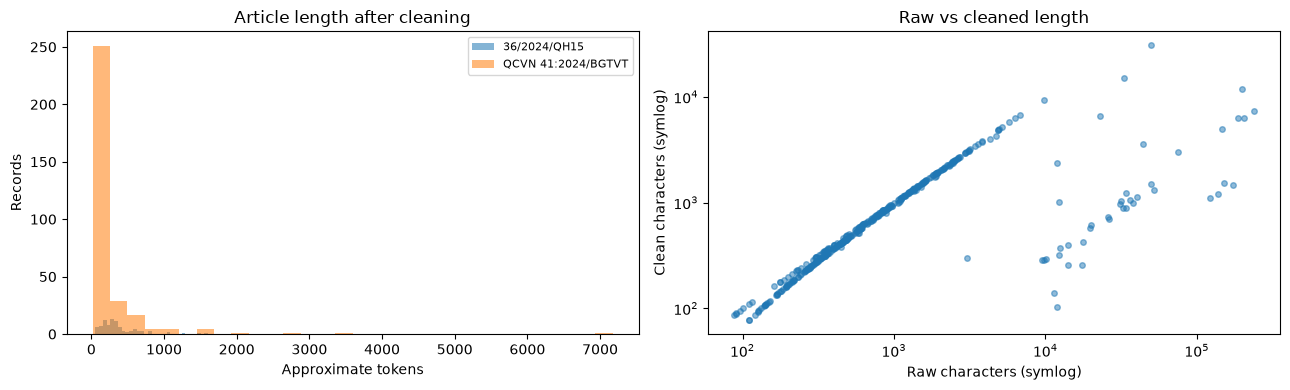

10 bản ghi dài nhất sau làm sạch:


,json_path,law_id,article_id,title,raw_chars,clean_chars,approx_tokens
267,$[0].articles[267],QCVN 41:2024/BGTVT,G.1,G.1. Vạch dọc đường,50133,30878,7171
46,$[0].articles[46],QCVN 41:2024/BGTVT,47,Các loại biển chỉ dẫn trên đường cao tốc,32929,15051,3398
45,$[0].articles[45],QCVN 41:2024/BGTVT,46,Nội dung biển chỉ dẫn trên đường cao tốc,199497,11767,2738
268,$[0].articles[268],QCVN 41:2024/BGTVT,G.2,G.2. Vạch ngang đường,9732,9283,2118
284,$[0].articles[284],QCVN 41:2024/BGTVT,M.4,M.4 Nhóm biển chỉ dẫn,238198,7334,1673
369,$[1].articles[56],36/2024/QH15,57,Giấy phép lái xe,6763,6755,1605
401,$[1].articles[88],36/2024/QH15,89,Quy định chuyển tiếp,6337,6325,1489
55,$[0].articles[55],QCVN 41:2024/BGTVT,56,Tiêu phản quang,22978,6648,1483
283,$[0].articles[283],QCVN 41:2024/BGTVT,M.3,M.3 Nhóm biển hiệu lệnh,188114,6319,1478
282,$[0].articles[282],QCVN 41:2024/BGTVT,M.2,M.2 Nhóm biển báo nguy hiểm và cảnh báo,203396,6371,1452


10 bản ghi ngắn nhất sau làm sạch:


,json_path,law_id,article_id,title,clean_chars,n_image_refs
277,$[0].articles[277],QCVN 41:2024/BGTVT,K.1,"K.1.2 Chữ thường, kiểu chữ thường (gt2)",77,1
276,$[0].articles[276],QCVN 41:2024/BGTVT,K.1,"K.1.1 Chữ in hoa, kiểu chữ thường (gt2)",77,1
83,$[0].articles[83],QCVN 41:2024/BGTVT,84,Tổ chức thực hiện,88,0
30,$[0].articles[30],QCVN 41:2024/BGTVT,31,Tác dụng của biển hiệu lệnh,95,0
9,$[0].articles[9],QCVN 41:2024/BGTVT,10,"Kích thước, hình dạng và các quy định khác của đèn tín hiệu",90,0
49,$[0].articles[49],QCVN 41:2024/BGTVT,50,Ý nghĩa sử dụng và kích thước của các vạch kẻ đường,87,0
231,$[0].articles[231],QCVN 41:2024/BGTVT,E.35a,"E.35a Biển số I.433a ""Nơi nghỉ mát""",87,1
70,$[0].articles[70],QCVN 41:2024/BGTVT,71,Các quy định khác,100,0
238,$[0].articles[238],QCVN 41:2024/BGTVT,E.40,"E.40 Biển số I.437 ""Đường cao tốc""",94,1
279,$[0].articles[279],QCVN 41:2024/BGTVT,K.2,"K.2.1 Chữ in hoa, kiểu chữ nén (gt1)",93,1


Rỗng sau làm sạch (có thể là bản ghi chỉ chứa ảnh):


,json_path,law_id,article_id,title,n_image_refs


In [7]:
display(articles.groupby('law_id')[['raw_chars', 'clean_chars', 'approx_tokens']]
        .describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for law_id, group in articles.groupby('law_id'):
    axes[0].hist(group['approx_tokens'], bins=30, alpha=0.55, label=law_id)
axes[0].set(title='Article length after cleaning', xlabel='Approximate tokens', ylabel='Records')
axes[0].legend(fontsize=8)
axes[1].scatter(articles['raw_chars'], articles['clean_chars'], alpha=0.5, s=16)
axes[1].set(xscale='symlog', yscale='symlog', title='Raw vs cleaned length',
            xlabel='Raw characters (symlog)', ylabel='Clean characters (symlog)')
plt.tight_layout()
plt.show()

print('10 bản ghi dài nhất sau làm sạch:')
display(articles.nlargest(10, 'approx_tokens')[
    ['json_path', 'law_id', 'article_id', 'title', 'raw_chars', 'clean_chars', 'approx_tokens']])
print('10 bản ghi ngắn nhất sau làm sạch:')
display(articles.nsmallest(10, 'approx_tokens')[
    ['json_path', 'law_id', 'article_id', 'title', 'clean_chars', 'n_image_refs']])
print('Rỗng sau làm sạch (có thể là bản ghi chỉ chứa ảnh):')
display(articles.loc[articles['clean_chars'] == 0,
    ['json_path', 'law_id', 'article_id', 'title', 'n_image_refs']])


## 7. Kiểm tra ảnh được tham chiếu

Ảnh corpus nằm trong `law_db/images.fld/`. Bỏ qua metadata macOS (`__MACOSX`, `.DS_Store`, file `._*`). Một ảnh có thể được nhiều bản ghi tham chiếu; ảnh chưa được tham chiếu không tự động là dữ liệu thừa cần xóa.


In [8]:
IMAGE_DIR = LAW_DIR / 'images.fld'
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f'Không tìm thấy thư mục ảnh: {IMAGE_DIR}')

image_refs = []
for row in articles.itertuples(index=False):
    for filename in IMAGE_PATTERN.findall(row.text):
        filename = filename.strip()
        target = (IMAGE_DIR / filename).resolve()
        inside_image_dir = target.is_relative_to(IMAGE_DIR.resolve())
        image_refs.append({
            'json_path': row.json_path,
            'law_id': row.law_id,
            'article_id': row.article_id,
            'filename': filename,
            'path': str(target),
            'exists': inside_image_dir and target.is_file(),
            'inside_image_dir': inside_image_dir,
        })
refs_df = pd.DataFrame(image_refs, columns=[
    'json_path', 'law_id', 'article_id', 'filename', 'path', 'exists', 'inside_image_dir'])
image_files = [p for p in IMAGE_DIR.rglob('*')
               if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.gif', '.bmp', '.webp'}
               and '__MACOSX' not in p.parts and not p.name.startswith('._')]
referenced_paths = {Path(p) for p in refs_df.loc[refs_df['exists'] == True, 'path']}
unused_files = [p for p in image_files if p.resolve() not in referenced_paths]
missing_refs = refs_df[refs_df['exists'] == False]

print('Lượt tham chiếu ảnh:', len(refs_df))
print('Tên ảnh được tham chiếu duy nhất:', refs_df['filename'].nunique())
print('File ảnh trên đĩa:', len(image_files))
print('Lượt tham chiếu không tìm thấy / đường dẫn không hợp lệ:', len(missing_refs))
print('File ảnh chưa được tham chiếu:', len(unused_files))
print('Phần mở rộng ảnh:', dict(Counter(p.suffix.lower() for p in image_files)))
display(missing_refs.head(30))
display(pd.DataFrame({'unreferenced_image': [str(p.relative_to(LAW_DIR)) for p in unused_files[:20]]}))


Lượt tham chiếu ảnh: 761
Tên ảnh được tham chiếu duy nhất: 761
File ảnh trên đĩa: 1576
Lượt tham chiếu không tìm thấy / đường dẫn không hợp lệ: 0
File ảnh chưa được tham chiếu: 815
Phần mở rộng ảnh: {'.png': 788, '.jpg': 788}


,json_path,law_id,article_id,filename,path,exists,inside_image_dir


,unreferenced_image
0,images.fld\image001.png
1,images.fld\image003.png
2,images.fld\image005.png
3,images.fld\image007.png
4,images.fld\image009.png
5,images.fld\image011.png
6,images.fld\image013.png
7,images.fld\image015.png
8,images.fld\image017.png
9,images.fld\image019.png


QCVN 41:2024/BGTVT 12 image002.jpg


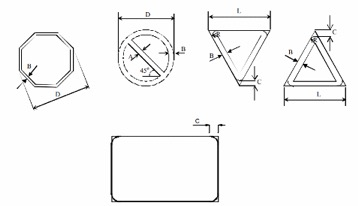

QCVN 41:2024/BGTVT 13 image004.jpg


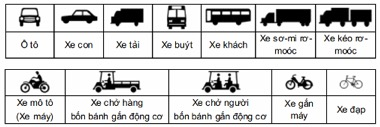

QCVN 41:2024/BGTVT 17 image006.jpg


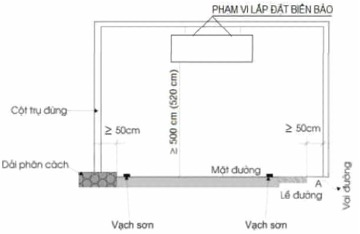

In [9]:
# Xem tối đa 3 ảnh có tham chiếu hợp lệ; chỉ hiển thị, không thay đổi ảnh.
samples = refs_df.loc[refs_df['exists'] == True].drop_duplicates('path').head(3)
for sample in samples.itertuples(index=False):
    print(sample.law_id, sample.article_id, sample.filename)
    display(Image(filename=sample.path, width=350))


## 8. Ghi nhận quyết định trước baseline

Sau khi chạy notebook, ghi kết luận của bạn ngay trong cell Markdown này:

- **Đơn vị truy xuất:** điều/mục theo dữ liệu gốc hay chunk? Baseline ban đầu có thể dùng điều/mục.
- **ID trùng:** đã kiểm tra nội dung và tiêu đề của các nhóm `K.1`, `K.2` chưa? Chọn gộp hay sửa ánh xạ sau khi xác minh; không tự ghi đè.
- **Văn bản index:** có nối tiêu đề văn bản, tiêu đề điều và nội dung không?
- **HTML/bảng:** cách chuyển sang văn bản có làm mất thông tin quan trọng không?
- **Ảnh:** baseline text-only bỏ thông tin ảnh; bản ghi chỉ có ảnh cần được ghi nhận riêng.
- **Độ dài:** có bản ghi quá dài cần thử chunking trong thực nghiệm sau không?
- **Định danh đầu ra:** luôn giữ cặp `(law_id, article_id)`.

Notebook này chưa đối chiếu nhãn `relevant_articles` của train/public test. Việc đó thuộc bước kiểm tra dữ liệu câu hỏi; không suy ra nhãn đúng/sai chỉ từ EDA corpus.
